# 06 · Validation: chronological splits, purging and rolling origins

**Goal:** understand why forecasting evaluation must respect time, how much a careless split can flatter a model, and how the pipeline structures train / validation / test.

Two ideas carry the notebook:
1. **A row is (series, origin, horizon, target).** Its *partition* is decided by the **origin** week, and a training row is only allowed if its **target** also lies inside the training window.
2. **The test window is used once**, after every choice has been made.

In [1]:
from tutorial_utils import *
style()
from sklearn.ensemble import HistGradientBoostingRegressor
rl = load_panel("realistic")
feats2 = build_features(rl, 2)
cols = columns_for(ABLATION_SETS["E4 +cross-market"])
print(f"{len(feats2)} rows for horizon 2; {len(cols)} features. Columns: {cols[:6]} ...")

2820 rows for horizon 2; 25 features. Columns: ['lr_1', 'lr_2', 'lr_4', 'lr_8', 'lr_13', 'dev_mean_4'] ...


## The timeline
* **Train** origins 1-104, **validation** origins 105-130, **test** origins 131-156 - the data span 156 weeks (2023-01-02 to 2025-12-22).
* For horizon *h*, a forecast issued at origin *t* is graded against week *t + h*.

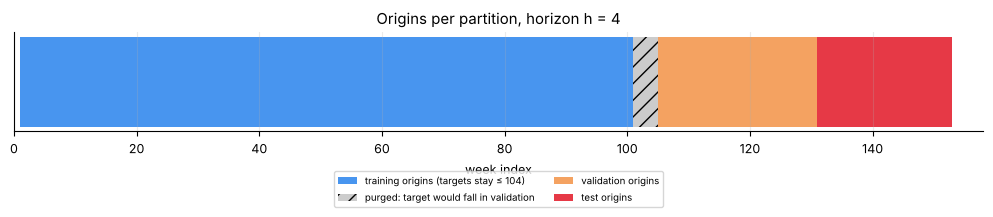

In [2]:
def timeline(h):
    fig, ax = plt.subplots(figsize=(10, 2.6))
    ax.barh(0, TRAIN_END - h, left=1, color="#4895ef", label=f"training origins (targets stay ≤ {TRAIN_END})")
    ax.barh(0, h, left=TRAIN_END - h + 1, color="#cccccc", hatch="//", label=f"purged: target would fall in validation")
    ax.barh(0, VAL_END - TRAIN_END, left=TRAIN_END + 1, color="#f4a261", label="validation origins")
    ax.barh(0, TEST_END - h - VAL_END, left=VAL_END + 1, color="#e63946", label="test origins")
    ax.set_yticks([]); ax.set_xlim(0, TEST_END + 2); ax.set_xlabel("week index"); ax.set_title(f"Origins per partition, horizon h = {h}")
    ax.legend(ncol=2, fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.35)); plt.tight_layout()
timeline(4)

**Purging (the grey hatched block).** A training row with origin 102 and horizon 4 has its *target* in week 106 - inside the validation window. If we trained on it, the model would have been shown a validation outcome.
So training rows must satisfy `target_week ≤ training end`, i.e. `origin ≤ training end − h`. How many rows does that remove?

In [3]:
rows = []
for h in HORIZONS:
    f = build_features(rl, h)
    naive_train = f[f.origin_week <= TRAIN_END]
    purged = f[f.origin_week <= TRAIN_END - h]
    rows.append(dict(horizon=h, rows_if_split_by_origin_only=len(naive_train), rows_after_purging=len(purged),
                     removed=len(naive_train) - len(purged), targets_that_would_be_in_validation=int((naive_train.target_week > TRAIN_END).sum())))
pd.DataFrame(rows)

,horizon,rows_if_split_by_origin_only,rows_after_purging,removed,targets_that_would_be_in_validation
0,1,1820,1800,20,20
1,2,1820,1780,40,40
2,4,1820,1740,80,80


The count is small (h origins × 20 series) - but a model fitted on those rows has "seen the answer" for the first validation weeks. In a persistent series even a few such rows matter, and they matter more at longer horizons.

## How much does a careless split flatter a model?
Fit the same model two ways using only data up to week 130 and compare the *measured* skill:

1. **Random 5-fold cross-validation** over all rows (shuffled) - the default in many tutorials.
2. **Chronological**: train on origins ≤ 104 − h, evaluate on origins 105-130.

and then look at what actually happened in the test window. We try a shallow model (gradient boosting, depth 3) and a high-capacity one (a fully grown random forest that can memorise near-duplicate rows),
at horizons 2 and 4.

In [4]:
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

def sk_model(kind):
    if kind == "shallow boosting":
        return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=150, max_depth=3, random_state=0)
    return make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=100, min_samples_leaf=1, max_features=1.0, random_state=0, n_jobs=1))

def design(frame):
    return pd.concat([frame[cols], pd.get_dummies(frame[["market_id", "crop_id"]]).astype(float)], axis=1)

def random_cv_skill(h, kind):
    f = build_features(rl, h)
    f = f[f.ref_price.notna() & f.y_obs.notna() & (f.y_obs > 0) & ~f.y_rejected & ~f.y_suspect]
    pool = f[f.origin_week <= VAL_END - h].reset_index(drop=True); X = design(pool)
    oof = np.full(len(pool), np.nan)
    for tr_idx, te_idx in KFold(5, shuffle=True, random_state=0).split(pool):
        oof[te_idx] = sk_model(kind).fit(X.iloc[tr_idx], pool.y.iloc[tr_idx]).predict(X.iloc[te_idx])
    return 1 - mae(pool.y_obs, pool.ref_price * np.exp(np.clip(oof, -1.2, 1.2))) / mae(pool.y_obs, pool.ref_price)

def forward_skill(h, kind, train_end, lo, hi):
    f = build_features(rl, h)
    params = dict(max_iter=150, max_depth=3, learning_rate=0.05) if kind == "shallow boosting" else dict(n_estimators=100, min_samples_leaf=1, max_features=1.0)
    p = fit_predict(f, cols, "hist_gb" if kind == "shallow boosting" else "random_forest", h, train_end, lo, eval_hi(h, hi), **params)
    return 1 - score(p) / score(naive_pred(f, lo, eval_hi(h, hi)))

rows = []
for h in (2, 4):
    for kind in ("shallow boosting", "deep random forest"):
        rows.append(dict(horizon=h, model=kind, random_CV_skill=random_cv_skill(h, kind) * 100,
                         chronological_validation_skill=forward_skill(h, kind, TRAIN_END, TRAIN_END + 1, VAL_END) * 100,
                         test_skill=forward_skill(h, kind, VAL_END, VAL_END + 1, TEST_END) * 100))
res = pd.DataFrame(rows); res["random-CV optimism (pp)"] = res.random_CV_skill - res.chronological_validation_skill
res.round(1)

,horizon,model,random_CV_skill,chronological_validation_skill,test_skill,random-CV optimism (pp)
0,2,shallow boosting,19.8,20.0,0.9,-0.2
1,2,deep random forest,20.6,17.8,2.8,2.8
2,4,shallow boosting,27.9,16.9,1.5,11.0
3,4,deep random forest,31.3,15.3,3.1,16.0


**How to read this** (skill versus naive, in %):
* At horizon 2 with a shallow model, random CV and chronological validation agree closely - here a careless split costs little.
* The optimism **grows with the horizon and with model capacity**: at h = 4, random CV reports roughly 28-31% skill where the honest chronological number is about 14-17%. Neighbouring weeks of the same series are near-duplicates (prices are persistent),
  and the five markets share weeks, so a flexible model can "interpolate" between rows it was shown instead of forecasting. A longer horizon makes the forecast problem harder, which makes the shortcut more tempting.
* The last column is the bigger message: **validation skill itself overstates the test**. The test window contains shocks absent from training (notebook 02), so even a perfectly honest validation can mislead.
  Chronological splits remove *one* source of optimism (leakage between neighbours); they cannot remove the optimism that comes from the future being different.

## Rolling-origin validation
One validation window is one roll of the dice - especially when the window contains a particular event. **Rolling origins** repeat the experiment: train up to week 65, validate on 66-78; train up to 78, validate on 79-91; and so on.
The training window *expands*, the validation window *moves forward*, nothing from the future ever enters training.

 fold  train_end  val_start  val_end
    1         65         66       78
    2         78         79       91
    3         91         92      104
    4        104        105      117
    5        117        118      130


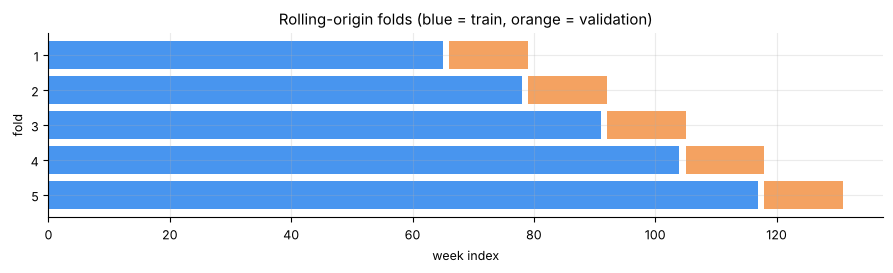

In [5]:
def rolling_folds(first_train_end=65, step=13, block=13, last=VAL_END):
    folds, te = [], first_train_end
    while te + block <= last:
        folds.append(dict(fold=len(folds) + 1, train_end=te, val_start=te + 1, val_end=te + block)); te += step
    return pd.DataFrame(folds)
folds = rolling_folds(); print(folds.to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 2.8))
for _, r in folds.iterrows():
    ax.barh(r.fold, r.train_end, color="#4895ef"); ax.barh(r.fold, r.val_end - r.val_start + 1, left=r.val_start, color="#f4a261")
ax.set_yticks(folds.fold); ax.set_xlabel("week index"); ax.set_ylabel("fold"); ax.set_title("Rolling-origin folds (blue = train, orange = validation)"); ax.invert_yaxis(); plt.tight_layout()

Now evaluate the same gradient-boosting model, and the naive forecast, in each fold (horizon 2):

In [6]:
rows = []
for _, r in folds.iterrows():
    p = fit_predict(feats2, cols, "hist_gb", 2, int(r.train_end), int(r.val_start), int(r.val_end))
    n = naive_pred(feats2, int(r.val_start), int(r.val_end))
    rows.append(dict(fold=int(r.fold), validation_weeks=f"{int(r.val_start)}-{int(r.val_end)}", model_MAE=score(p), naive_MAE=score(n)))
cv = pd.DataFrame(rows); cv["skill %"] = (1 - cv.model_MAE / cv.naive_MAE) * 100
print(cv.round(2).to_string(index=False))
print(f"\nmean skill {cv['skill %'].mean():.1f}%   spread across folds (std): {cv['skill %'].std():.1f} percentage points")

 fold validation_weeks  model_MAE  naive_MAE  skill %
    1            66-78       5.02       5.61    10.48
    2            79-91       3.07       3.29     6.72
    3           92-104       2.90       3.57    18.85
    4          105-117       4.13       4.82    14.26
    5          118-130       3.65       4.90    25.68

mean skill 15.2%   spread across folds (std): 7.4 percentage points


The skill differs noticeably from fold to fold: some windows are easier for the model than others. If you had looked at only one of them you could have drawn quite different conclusions.
That variability is also a warning about *the test window*: it is one more window, and an unusually hard one by design.

The pipeline uses these five folds for **all tuning and for the "repeatable improvement" selection rule**: a complex model is only preferred if it wins in nearly all folds *and* by a meaningful margin
over the strongest baseline (specification section 15).

## Rules of the road
1. **Origin decides the partition**; **target must lie inside the training window** (purging).
2. **Statistics are learned from training rows only** (notebook 05).
3. **Tune on rolling folds up to the end of validation**; the test window never participates.
4. **Choose first, then test once.** Everything - features, hyper-parameters, which model to call best - is fixed before looking at the test window. Looking at test results and then changing the model turns the test into a second validation set.
5. **Report validation and test separately** - a large gap is a finding, not an embarrassment (notebook 10: every model degraded 24-44% from validation to test).

## Exercises
1. Add `h = 1` to the experiment. Does the random-CV optimism shrink further? Add a third model (Ridge): how much optimism does a *linear* model get from a random split?
2. Change `rolling_folds` to use a **sliding** (fixed-size) training window instead of an expanding one. When might that be preferable?
3. Deliberately *remove* the purge: train the chronological model on origins ≤ 104 (not 104 − h) and compare validation skill. How big is the effect?
4. Increase the number of folds by halving `step` and `block`. Does the average skill change? Does the spread?

**Where this lives in the pipeline:** `src/agriprice/splits.py` (`partitions`, `rolling_folds`, `train_rows`), the purge test in `tests/test_no_leakage.py::test_training_rows_are_purged`.